In [1]:
import pandas as pd
import os

print("Posisi folder saat ini:", os.getcwd())
print("Isi folder data/raw:")
if os.path.exists("../data/raw"):
    print(os.listdir("../data/raw"))
else:
    print("Folder tidak ditemukan")
    

Posisi folder saat ini: c:\Games\PR\urlinsight-ml\notebooks
Isi folder data/raw:
['PhiUSIIL_Phishing_URL_Dataset.csv', 'url_features_extracted1.csv']


In [2]:
import pandas as pd

# 1. LOAD DATASET (Pakai nama file yang baru kita temukan)
print("=== MEMBACA DATASET ===")
df_phiusiil = pd.read_csv("../data/raw/PhiUSIIL_Phishing_URL_Dataset.csv")
df_legit = pd.read_csv("../data/raw/url_features_extracted1.csv")

# 2. CEK NAMA KOLOM
print("\n=== NAMA KOLOM PHIUSIIL ===")
print(df_phiusiil.columns.tolist())
print("\n=== NAMA KOLOM LEGIT ===")
print(df_legit.columns.tolist())

# 3. CEK 3 DATA TERATAS (Biar tahu bentuknya)
print("\n=== 3 DATA TERATAS PHIUSIIL ===")
print(df_phiusiil.head(3))

print("\n=== 3 DATA TERATAS LEGIT ===")
print(df_legit.head(3)) 

=== MEMBACA DATASET ===

=== NAMA KOLOM PHIUSIIL ===
['FILENAME', 'URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef', 'label']

=== NAMA KOLOM LEGIT ===
['

In [3]:
# 1. CEK JUMLAH DATA
print("=== JUMLAH DATA ===")
print("PhiUSIIL:", df_phiusiil.shape)
print("Legit   :", df_legit.shape)

# 2. CEK DISTRIBUSI LABEL (Berapa phishing, berapa legit)
print("\n=== DISTRIBUSI LABEL ===")
print("PhiUSIIL (label):")
print(df_phiusiil['label'].value_counts())

print("\nLegit (ClassLabel):")
print(df_legit['ClassLabel'].value_counts())

# 3. CEK DATA KOSONG (NaN) DI KOLOM URL
print("\n=== CEK DATA KOSONG ===")
print("PhiUSIIL URL kosong:", df_phiusiil['URL'].isna().sum())
print("Legit URL kosong   :", df_legit['URL'].isna().sum())

# 4. CEK URL GANDA (DUPLIKAT)
print("\n=== CEK DUPLIKAT URL ===")
print("Duplikat di PhiUSIIL:", df_phiusiil.duplicated(subset=['URL']).sum())
print("Duplikat di Legit   :", df_legit.duplicated(subset=['URL']).sum())

# 5. CEK APAKAH ADA URL YANG SAMA DI KEDUA DATASET (Ini penting untuk uji lintas dataset!)
# Kita ubah ke set (himpunan) agar cepat mengeceknya
set_url_phi = set(df_phiusiil['URL'])
set_url_legit = set(df_legit['URL'])
irisan_url = set_url_phi.intersection(set_url_legit)
print("\n=== URL YANG ADA DI KEDUA DATASET ===")
print("Jumlah URL yang tumpang tindih:", len(irisan_url))

=== JUMLAH DATA ===
PhiUSIIL: (235795, 56)
Legit   : (101219, 18)

=== DISTRIBUSI LABEL ===
PhiUSIIL (label):
label
1    134850
0    100945
Name: count, dtype: int64

Legit (ClassLabel):
ClassLabel
0.0    63678
1.0    37540
Name: count, dtype: int64

=== CEK DATA KOSONG ===
PhiUSIIL URL kosong: 0
Legit URL kosong   : 0

=== CEK DUPLIKAT URL ===
Duplikat di PhiUSIIL: 425
Duplikat di Legit   : 346

=== URL YANG ADA DI KEDUA DATASET ===
Jumlah URL yang tumpang tindih: 36936


In [4]:
# 1. Hapus duplikat di dalam masing-masing dataset
df_phiusiil_clean = df_phiusiil.drop_duplicates(subset=['URL']).copy()
df_legit_clean = df_legit.drop_duplicates(subset=['URL']).copy()

# 2. Hapus URL yang tumpang tindih (ada di kedua dataset)
# Kita ambil URL dari dataset PhiUSIIL, lalu buang dari dataset Legit
df_legit_clean = df_legit_clean[~df_legit_clean['URL'].isin(df_phiusiil_clean['URL'])]

# 3. Cek ulang hasilnya
print("=== SETELAH DIBERSIHKAN ===")
print("Jumlah PhiUSIIL:", df_phiusiil_clean.shape)
print("Jumlah Legit   :", df_legit_clean.shape)

# 4. Cek apakah masih ada yang tumpang tindih
set_url_phi = set(df_phiusiil_clean['URL'])
set_url_legit = set(df_legit_clean['URL'])
irisan_akhir = set_url_phi.intersection(set_url_legit)
print("\nSisa URL tumpang tindih:", len(irisan_akhir))

=== SETELAH DIBERSIHKAN ===
Jumlah PhiUSIIL: (235370, 56)
Jumlah Legit   : (63937, 18)

Sisa URL tumpang tindih: 0


In [5]:
import math
from collections import Counter
from urllib.parse import urlparse

# Fungsi untuk menghitung Entropy (Keacakan)
def shannon_entropy(s):
    if not s:
        return 0.0
    n = len(s)
    return -sum(c / n * math.log2(c / n) for c in Counter(s).values())

# Fungsi Utama Ekstraksi Fitur
def extract_features(url):
    # Pastikan url berupa string
    url = str(url)
    host = urlparse(url).netloc
    
    fitur = [
        len(url),                                      # url_length
        url.count("."),                                # dot_count
        sum(ch.isdigit() for ch in url),               # digit_count
        int(url.startswith("https://")),               # is_https (1 jika https, 0 jika tidak)
        len(host),                                     # domain_length
        shannon_entropy(url)                           # entropy
    ]
    return fitur

# Uji coba fungsi ke 1 URL
contoh_url = "https://www.bca.co.id/login"
print("Fitur untuk URL:", contoh_url)
print(extract_features(contoh_url))

Fitur untuk URL: https://www.bca.co.id/login
[27, 3, 0, 1, 13, 3.930270372293453]


In [6]:
# 1. Tentukan nama-nama kolom untuk fitur yang kita buat
FEATURE_NAMES = ["url_length", "dot_count", "digit_count", "is_https", "domain_length", "entropy"]

print("Sedang memproses data PhiUSIIL... (mungkin butuh beberapa detik)")
# 2. Ekstrak semua URL di dataset PhiUSIIL
X_phi = pd.DataFrame(df_phiusiil_clean['URL'].apply(extract_features).tolist(), columns=FEATURE_NAMES)
y_phi = df_phiusiil_clean['label']

print("Sedang memproses data LegitPhish...")
# 3. Ekstrak semua URL di dataset LegitPhish
X_legit = pd.DataFrame(df_legit_clean['URL'].apply(extract_features).tolist(), columns=FEATURE_NAMES)
y_legit = df_legit_clean['ClassLabel']

print("\n=== PROSES EKSTRAKSI SELESAI ===")
print("Bentuk Data X_phi (Fitur PhiUSIIL):", X_phi.shape)
print("Bentuk Data y_phi (Label PhiUSIIL):", y_phi.shape)
print("Bentuk Data X_legit (Fitur Legit):", X_legit.shape)
print("Bentuk Data y_legit (Label Legit):", y_legit.shape)

# 4. Tampilkan 5 data teratas hasil ekstraksi
print("\nContoh Hasil Ekstraksi (X_phi):")
print(X_phi.head())

Sedang memproses data PhiUSIIL... (mungkin butuh beberapa detik)
Sedang memproses data LegitPhish...

=== PROSES EKSTRAKSI SELESAI ===
Bentuk Data X_phi (Fitur PhiUSIIL): (235370, 6)
Bentuk Data y_phi (Label PhiUSIIL): (235370,)
Bentuk Data X_legit (Fitur Legit): (63937, 6)
Bentuk Data y_legit (Label Legit): (63937,)

Contoh Hasil Ekstraksi (X_phi):
   url_length  dot_count  digit_count  is_https  domain_length   entropy
0          32          2            0         1             24  3.929229
1          24          2            0         1             16  3.970176
2          30          3            0         1             22  4.164735
3          27          2            0         1             19  4.060262
4          34          2            0         1             26  3.917626


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report
import joblib
import os

# Pastikan folder models sudah ada
if not os.path.exists('../models'):
    os.makedirs('../models')

# 1. Bagi data PhiUSIIL menjadi Data Latih (80%) dan Data Uji (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X_phi, y_phi, test_size=0.2, stratify=y_phi, random_state=42
)

print("Jumlah Data Latih:", X_train.shape[0])
print("Jumlah Data Uji  :", X_test.shape[0])

# ==========================================
# 2. LATIH MODEL UTAMA: RANDOM FOREST
# ==========================================
print("\nMelatih Random Forest...")
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Uji model RF
y_pred_rf = rf_model.predict(X_test)
print("\n=== HASIL UJI RANDOM FOREST (Data Internal PhiUSIIL) ===")
print(f"Akurasi: {accuracy_score(y_test, y_pred_rf) * 100:.2f}%")
print(classification_report(y_test, y_pred_rf))

# ==========================================
# 3. LATIH MODEL PEMBANDING: LOGISTIC REGRESSION
# ==========================================
print("\nMelatih Logistic Regression...")
# LR butuh scaling, jadi kita bungkus pakai Pipeline
lr_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
lr_model.fit(X_train, y_train)

# Uji model LR
y_pred_lr = lr_model.predict(X_test)
print("\n=== HASIL UJI LOGISTIC REGRESSION (Data Internal PhiUSIIL) ===")
print(f"Akurasi: {accuracy_score(y_test, y_pred_lr) * 100:.2f}%")
print(classification_report(y_test, y_pred_lr))

# ==========================================
# 4. SIMPAN MODEL KE FOLDER 'models/'
# ==========================================
print("\nMenyimpan model ke folder models/...")
joblib.dump(rf_model, '../models/rf_baseline.joblib')
joblib.dump(lr_model, '../models/lr_baseline.joblib')
print("Model berhasil disimpan!")

Jumlah Data Latih: 188296
Jumlah Data Uji  : 47074

Melatih Random Forest...

=== HASIL UJI RANDOM FOREST (Data Internal PhiUSIIL) ===
Akurasi: 99.39%
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     20104
           1       0.99      1.00      0.99     26970

    accuracy                           0.99     47074
   macro avg       0.99      0.99      0.99     47074
weighted avg       0.99      0.99      0.99     47074


Melatih Logistic Regression...

=== HASIL UJI LOGISTIC REGRESSION (Data Internal PhiUSIIL) ===
Akurasi: 97.16%
              precision    recall  f1-score   support

           0       1.00      0.94      0.97     20104
           1       0.96      1.00      0.98     26970

    accuracy                           0.97     47074
   macro avg       0.98      0.97      0.97     47074
weighted avg       0.97      0.97      0.97     47074


Menyimpan model ke folder models/...
Model berhasil disimpan!


In [8]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Siapkan list kosong untuk menyimpan hasil
hasil_evaluasi = []

# ==========================================
# FUNGSI BANTU UNTUK MENCATAT HASIL
# ==========================================
def catat_hasil(skenario, model_name, y_true, y_pred):
    hasil_evaluasi.append({
        "Skenario": skenario,
        "Model": model_name,
        "Accuracy": round(accuracy_score(y_true, y_pred), 4),
        "Precision": round(precision_score(y_true, y_pred), 4),
        "Recall": round(recall_score(y_true, y_pred), 4),
        "F1-Score": round(f1_score(y_true, y_pred), 4)
    })

# ==========================================
# S1: PhiUSIIL -> PhiUSIIL (Sudah kita hitung, kita catat saja)
# ==========================================
catat_hasil("S1 (Phi -> Phi)", "Random Forest", y_test, y_pred_rf)
catat_hasil("S1 (Phi -> Phi)", "Logistic Regression", y_test, y_pred_lr)

# ==========================================
# S2: LegitPhish -> LegitPhish (Uji Internal Legit)
# ==========================================
print("Melatih model untuk S2...")
# Split data Legit
Xl_train, Xl_test, yl_train, yl_test = train_test_split(
    X_legit, y_legit, test_size=0.2, stratify=y_legit, random_state=42
)
# Latih RF
rf_legit = RandomForestClassifier(n_estimators=100, random_state=42).fit(Xl_train, yl_train)
catat_hasil("S2 (Legit -> Legit)", "Random Forest", yl_test, rf_legit.predict(Xl_test))
# Latih LR
lr_legit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)).fit(Xl_train, yl_train)
catat_hasil("S2 (Legit -> Legit)", "Logistic Regression", yl_test, lr_legit.predict(Xl_test))

# ==========================================
# S3: PhiUSIIL -> LegitPhish (Uji Lintas Arah 1)
# ==========================================
print("Menguji S3 (Uji Lintas Arah 1)...")
# Pakai model rf_model dan lr_model yang sudah dilatih dari PhiUSIIL, lalu uji ke SELURUH data Legit
catat_hasil("S3 (Phi -> Legit)", "Random Forest", y_legit, rf_model.predict(X_legit))
catat_hasil("S3 (Phi -> Legit)", "Logistic Regression", y_legit, lr_model.predict(X_legit))

# ==========================================
# S4: LegitPhish -> PhiUSIIL (Uji Lintas Arah 2)
# ==========================================
print("Menguji S4 (Uji Lintas Arah 2)...")
# Pakai model rf_legit dan lr_legit yang dilatih dari Legit, lalu uji ke SELURUH data PhiUSIIL
catat_hasil("S4 (Legit -> Phi)", "Random Forest", y_phi, rf_legit.predict(X_phi))
catat_hasil("S4 (Legit -> Phi)", "Logistic Regression", y_phi, lr_legit.predict(X_phi))

# Tampilkan Tabel Hasil Akhir
df_hasil = pd.DataFrame(hasil_evaluasi)
print("\n=== TABEL HASIL EVALUASI LENGKAP ===")
print(df_hasil.to_string(index=False))

Melatih model untuk S2...
Menguji S3 (Uji Lintas Arah 1)...
Menguji S4 (Uji Lintas Arah 2)...

=== TABEL HASIL EVALUASI LENGKAP ===
           Skenario               Model  Accuracy  Precision  Recall  F1-Score
    S1 (Phi -> Phi)       Random Forest    0.9939     0.9927  0.9967    0.9947
    S1 (Phi -> Phi) Logistic Regression    0.9716     0.9555  0.9969    0.9758
S2 (Legit -> Legit)       Random Forest    0.9980     0.9200  0.7753    0.8415
S2 (Legit -> Legit) Logistic Regression    0.9934     0.5862  0.1910    0.2881
  S3 (Phi -> Legit)       Random Forest    0.9931     0.8889  0.0180    0.0352
  S3 (Phi -> Legit) Logistic Regression    0.9935     0.7059  0.1079    0.1871
  S4 (Legit -> Phi)       Random Forest    0.7714     0.9452  0.6380    0.7618
  S4 (Legit -> Phi) Logistic Regression    0.4213     0.0000  0.0000    0.0000


Matplotlib is building the font cache; this may take a moment.


Tabel berhasil disimpan di folder docs/


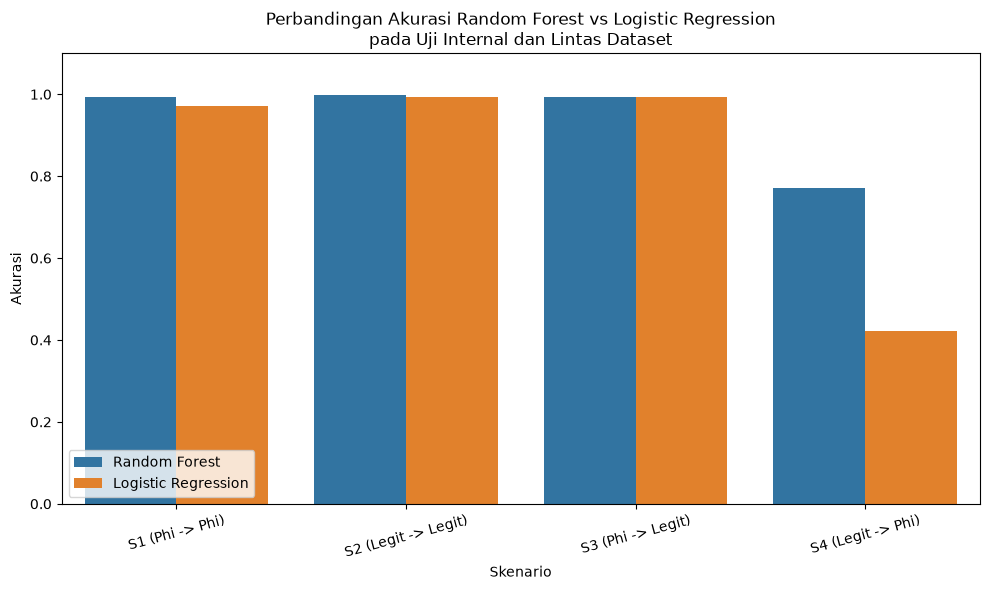

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Simpan tabel ke CSV
df_hasil.to_csv("../docs/hasil_evaluasi_S1_S4.csv", index=False)
print("Tabel berhasil disimpan di folder docs/")

# 2. Bikin Grafik Perbandingan Akurasi
plt.figure(figsize=(10, 6))
sns.barplot(data=df_hasil, x="Skenario", y="Accuracy", hue="Model")
plt.title("Perbandingan Akurasi Random Forest vs Logistic Regression\npada Uji Internal dan Lintas Dataset")
plt.ylim(0, 1.1) # Batas Y dari 0 sampai 1
plt.ylabel("Akurasi")
plt.xticks(rotation=15) # Miringkan teks sumbu X biar ga tabrakan
plt.legend(loc="lower left")
plt.tight_layout()

# 3. Simpan gambar grafiknya
plt.savefig("../docs/grafik_akurasi.png", dpi=300)
plt.show()